# 🍔 Kuşak Çatışması: Adım Adım Analiz

Yemek sipariş uygulamalarında **Z kuşağı** ile **diğer kuşakların** alışkanlık, ekonomik algı ve sadakat farklarını, genişletilmiş **UTAUT2** modeliyle inceleyen anket çalışmasının analiz defteri.

| # | Bölüm | Soru |
|---|---|---|
| 1 | Örneklem | Kimlerle konuştuk? |
| 2 | Ölçüm modeli | Ölçekler güvenilir ve birbirinden ayrışıyor mu? |
| 3 | Kuşak karşılaştırması | Z kuşağı hangi algılarda farklı? |
| 4 | Yapısal model (PLS-SEM) | Sadakati ne belirliyor? |
| 5 | Ekonomik algı | Refah algısı duygu ve fiyatın etkisini değiştiriyor mu? |
| 6 | Çok gruplu analiz | Sadakat mekanizması kuşaklarda aynı mı? |
| 7 | Önem-performans haritası | Sadakat için nereye yatırım yapılmalı? |
| 8 | Güç analizi | 236 kişi yeterli mi? |

> 🔒 **Veri hakkında:** Ham anket verisi katılımcı gizliliği nedeniyle paylaşılmaz. Bu defter, ham veri varsa (`data/private/`) onunla, yoksa repodaki **sentetik veriyle** çalışır. nbviewer'da gördüğün çıktılar **gerçek veriden** üretilmiştir; Colab'da çalıştırdığında sonuçlar sentetik veriye ait olacağı için biraz farklı çıkar. Defter hiçbir yerde tek tek katılımcı yanıtı göstermez, yalnızca toplu sonuçlar sunar.

In [1]:
# Colab'da açıldıysa repoyu indir
import os, sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("analysis").exists():
    !git clone -q https://github.com/Memreu/Kusak-Catismasi.git
    %cd Kusak-Catismasi

ROOT = Path.cwd() if Path("analysis").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "analysis" / "python"))

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

import kusak_analiz as ka
from pls_sem import PLSModel

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3)

ozel = ROOT / "data" / "private" / "analiz_verisi.csv"
GERCEK = ozel.exists()
d = pd.read_csv(ozel if GERCEK else ROOT / "data" / "sentetik_veri.csv")
for lv, cols in ka.BLOCKS.items():
    d[lv] = d[cols].mean(axis=1)

print(("✅ GERÇEK veri" if GERCEK else "🧪 SENTETİK veri (sonuçlar yalnızca kodu göstermek içindir)") + f" · n = {len(d)}")

✅ GERÇEK veri · n = 236


## 1. Örneklem

Filtrelemeden (dikkat kontrolü, son 6 ayda sipariş vermemiş olanlar, tekdüze yanıtlar) sonra kalan katılımcıların profili. Tablolar yalnızca toplu sayıları gösterir.

In [3]:
profil = {
    "Kuşak": d.kusak.value_counts(),
    "Cinsiyet": d.cinsiyet.value_counts(),
    "Ekonomik algı": d.eko_durum.value_counts().reindex(["Kötü", "Orta", "İyi"]),
    "Şehir": d.sehir_grup.value_counts(),
}
pd.concat({k: pd.DataFrame({"n": v, "%": (100 * v / v.sum()).round(1)}) for k, v in profil.items()})

n     %
Kuşak         Z           129  54.7
              Diğer       107  45.3
Cinsiyet      Erkek       124  52.5
              Kadın       112  47.5
Ekonomik algı Kötü         19   8.1
              Orta        124  52.5
              İyi          93  39.4
Şehir         Büyükşehir  163  69.1
              Diğer        73  30.9

## 2. Ölçüm modeli

Altı yapı, 19 Likert maddesiyle ölçüldü. PLS ölçüm modeliyle her yapının iç tutarlılığı (Cronbach α, birleşik güvenilirlik ρc), yakınsak geçerliliği (AVE) ve yapıların birbirinden ayrışması (HTMT) kontrol edilir.

In [4]:
model = PLSModel(ka.BLOCKS, ka.PATHS)
pls = model.fit(d)
rel = pls.reliability.rename(index=ka.NAMES)
rel.style.format("{:.3f}").background_gradient(cmap="Greens", vmin=0.5, vmax=0.9)

,alpha,rho_c,AVE
Performans beklentisi,0.730,0.847,0.648
Çaba beklentisi,0.809,0.887,0.723
Duygusal değer,0.681,0.821,0.605
Fiyat değeri,0.663,0.817,0.599
Alışkanlık,0.799,0.871,0.629
Sadakat,0.627,0.804,0.579


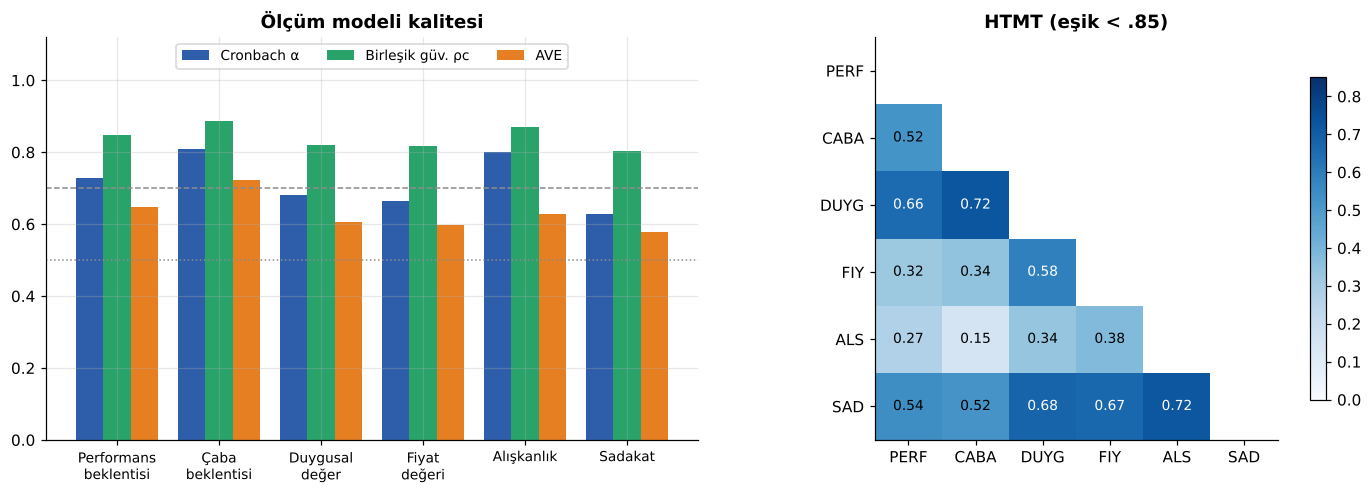

En yüksek HTMT: 0.725 (eşik .85) · en yüksek madde VIF: 2.63 (eşik 5)


In [5]:
ka.grafik_htmt(pls)
print(f"En yüksek HTMT: {np.nanmax(pls.htmt.to_numpy()):.3f} (eşik .85) · en yüksek madde VIF: {pls.outer_vif.max():.2f} (eşik 5)")

**Yorum:** Tüm yapılarda ρc 0,80'in, AVE 0,50'nin üzerinde; duygusal değer, fiyat değeri ve sadakatin α değerleri 0,60–0,70 arasında, yani kabul edilebilir ama ideal değil. HTMT değerlerinin tamamı 0,85'in altında: altı yapı birbirinden ayrışıyor.

## 3. Kuşak karşılaştırması

H4a, Z kuşağının "dijital yerli" olduğu için uygulamayı daha fazla alışkanlığa dönüştürdüğünü öngörüyordu. Altı yapının tamamı iki grupta bağımsız örneklem t-testiyle karşılaştırılır.

,yapı,Z ort.,Diğer ort.,t,p,Cohen d
0,Performans beklentisi,5.731,5.757,-0.195,0.846,-0.025
1,Çaba beklentisi,5.827,5.841,-0.102,0.919,-0.013
2,Duygusal değer,4.891,5.302,-2.653,0.009,-0.347
3,Fiyat değeri,4.209,4.576,-2.228,0.027,-0.291
4,Alışkanlık,3.500,3.998,-2.636,0.009,-0.345
5,Sadakat,4.824,5.009,-1.418,0.157,-0.185


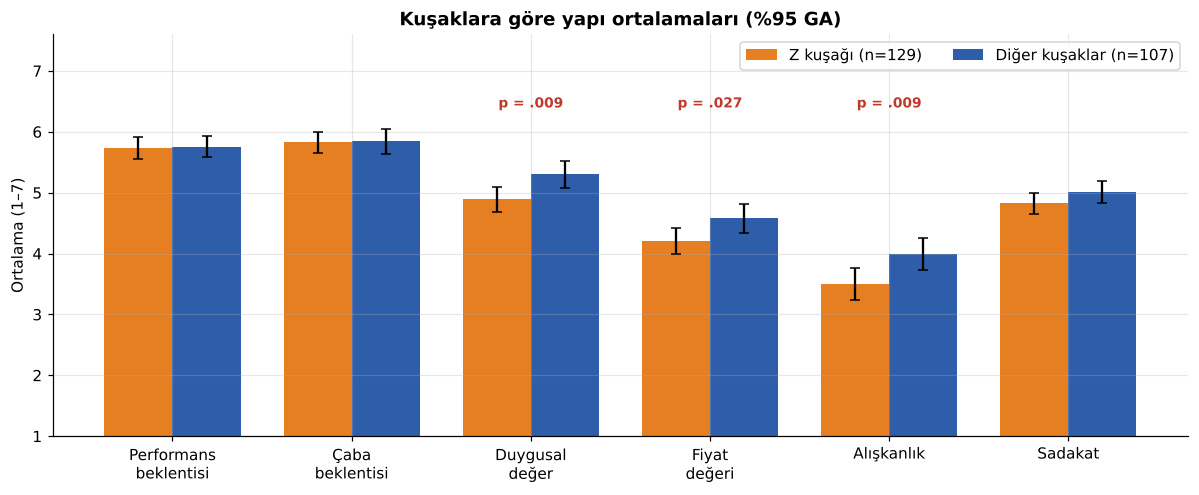

In [6]:
def t_tablo(grup, a, b):
    rows = []
    for k in ka.BLOCKS:
        x, y = d.loc[d[grup] == a, k], d.loc[d[grup] == b, k]
        t = stats.ttest_ind(x, y)
        sp = np.sqrt(((len(x) - 1) * x.var() + (len(y) - 1) * y.var()) / (len(x) + len(y) - 2))
        rows.append({"yapı": ka.NAMES[k], f"{a} ort.": x.mean(), f"{b} ort.": y.mean(),
                     "t": t.statistic, "p": t.pvalue, "Cohen d": (x.mean() - y.mean()) / sp})
    return pd.DataFrame(rows)

t_kusak = t_tablo("kusak", "Z", "Diğer")
display(t_kusak.style.format(precision=3).apply(
    lambda r: ["background-color: #FDEBD0" if r.p < 0.05 else "" for _ in r], axis=1))
ka.grafik_kusak(d, t_kusak)

**Yorum:** H4a **ters yönde** sonuç verdi. Z kuşağı uygulamayı diğer kuşaklar kadar kullanışlı ve kolay buluyor, ama ondan daha az duygusal ve ekonomik değer algılıyor ve daha az alışkanlık geliştiriyor. Sadakatte ise anlamlı fark yok (H4b reddedildi).

## 4. Yapısal model (PLS-SEM)

Performans ve çaba beklentisi **değer algısını** (duygusal ve fiyat), değer algısı ve alışkanlık da **sadakati** yordar. Katsayıların anlamlılığı bootstrap ile test edilir.

In [7]:
N_BOOT = 1000
boot = model.bootstrap(d, n_boot=N_BOOT, indirect=[("PERF", "DUYG", "SAD"), ("CABA", "DUYG", "SAD"),
                                                   ("PERF", "FIY", "SAD"), ("CABA", "FIY", "SAD")])
boot = boot.merge(pls.f2.assign(yol=pls.f2.kaynak + " → " + pls.f2.hedef)[["yol", "f2"]], on="yol", how="left")
print("R²:", ", ".join(f"{ka.NAMES[k]} = {v:.3f}" for k, v in pls.r2.items()))
boot.style.format(precision=3, na_rep="")

R²: Duygusal değer = 0.411, Fiyat değeri = 0.085, Sadakat = 0.431


,yol,katsayi,std_hata,t,p,ga_alt,ga_ust,f2
0,PERF → DUYG,0.306,0.069,4.464,0.000,0.175,0.446,0.134
1,CABA → DUYG,0.454,0.066,6.862,0.000,0.315,0.577,0.294
2,PERF → FIY,0.152,0.073,2.084,0.038,0.003,0.286,0.021
3,CABA → FIY,0.196,0.073,2.672,0.008,0.053,0.341,0.035
4,DUYG → SAD,0.277,0.064,4.311,0.000,0.149,0.398,0.113
5,FIY → SAD,0.223,0.062,3.564,0.000,0.102,0.348,0.071
6,ALS → SAD,0.398,0.056,7.135,0.000,0.285,0.504,0.252
7,PERF → DUYG → SAD,0.085,0.025,3.370,0.001,0.040,0.136,
8,CABA → DUYG → SAD,0.126,0.036,3.452,0.001,0.054,0.200,
9,PERF → FIY → SAD,0.034,0.020,1.680,0.094,0.001,0.078,


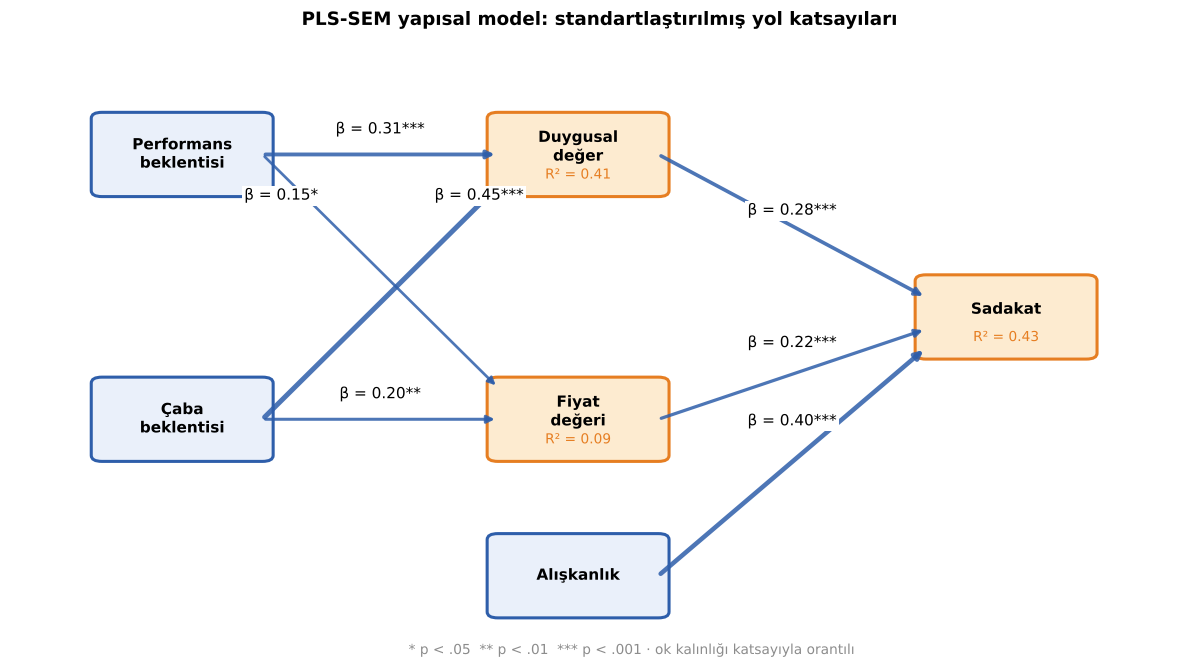

In [8]:
ka.grafik_model(pls, boot)

**Yorum:**

- Sadakatin en güçlü yordayıcısı **alışkanlık**; duygusal değer ve fiyat değeri onu izliyor. Model sadakatteki varyansın yaklaşık %43'ünü açıklıyor.
- Duygusal değerin ana kaynağı **kullanım kolaylığı** (çaba beklentisi, f² ≈ 0,29): "En sevilen uygulama, en az yoran uygulamadır."
- Performans ve çaba beklentisinin sadakate etkisi büyük ölçüde **duygusal değer üzerinden** taşınıyor (dolaylı etkiler anlamlı); fiyat değeri üzerinden dolaylı etkiler sınırda.

## 5. Ekonomik algı

H6: Ekonomik durumunu kötü algılayanlarda fiyatın, iyi algılayanlarda duygunun daha belirleyici olması bekleniyordu. Her ekonomik algı grubunda değer → sadakat eğimleri ayrı ayrı hesaplanır ve etkileşimler F testiyle sınanır.

Duygusal değer × ekonomik algı: ΔR² = 0.024, F = 3.59, p = 0.029
Fiyat değeri × ekonomik algı: ΔR² = 0.039, F = 5.88, p = 0.003


,ekonomik algı,n,β (duygusal değer),p (duygusal değer),β (fiyat değeri),p (fiyat değeri)
0,Kötü,19,0.284,0.239,0.489,0.034
1,Orta,124,0.544,0.000,0.581,0.000
2,İyi,93,0.330,0.001,0.241,0.020


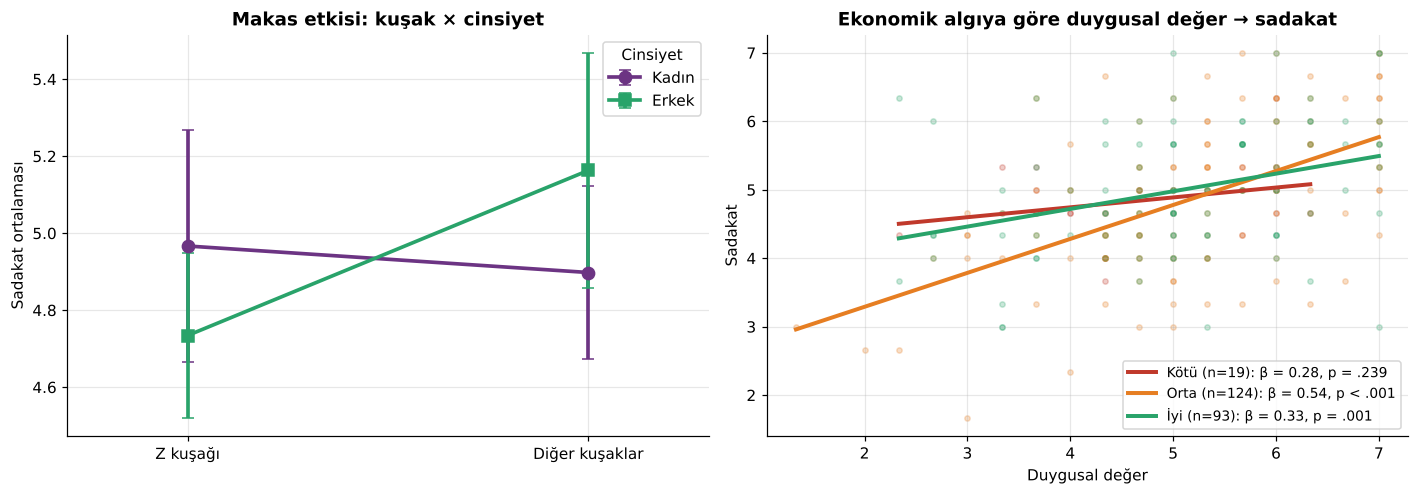

In [9]:
c = d.assign(eko=pd.Categorical(d.eko_durum, ["Kötü", "Orta", "İyi"]),
             DUYG_c=d.DUYG - d.DUYG.mean(), FIY_c=d.FIY - d.FIY.mean())
for x in ["DUYG_c", "FIY_c"]:
    m0 = smf.ols(f"SAD ~ {x} + C(eko)", c).fit()
    m1 = smf.ols(f"SAD ~ {x} * C(eko)", c).fit()
    f, p, _ = m1.compare_f_test(m0)
    print(f"{ka.NAMES[x[:-2]]} × ekonomik algı: ΔR² = {m1.rsquared - m0.rsquared:.3f}, F = {f:.2f}, p = {p:.3f}")

z = lambda s: (s - s.mean()) / s.std()
egimler = []
for g in ["Kötü", "Orta", "İyi"]:
    s = d[d.eko_durum == g]
    row = {"ekonomik algı": g, "n": len(s)}
    for x in ["DUYG", "FIY"]:
        m = smf.ols(f"SAD ~ {x}", s.assign(SAD=z(s.SAD), **{x: z(s[x])})).fit()
        row[f"β ({ka.NAMES[x].lower()})"], row[f"p ({ka.NAMES[x].lower()})"] = m.params[x], m.pvalues[x]
    egimler.append(row)
egimler = pd.DataFrame(egimler)
display(egimler.style.format(precision=3))
ka.grafik_makas_eko(d, egimler)

**Yorum:** Ekonomik durumunu kötü algılayanlarda duygusal değerin sadakate etkisi anlamsız, fiyat değerininki anlamlı. Ekonomik algı iyileştikçe fiyatın etkisi en düşük seviyeye iniyor. Kötü algı grubu küçük (n = 19) olduğu için bu grubun sonuçları temkinli okunmalı. Soldaki grafik, kuşak × cinsiyet etkileşimindeki "makas" eğilimini gösteriyor (sınırda anlamlı).

## 6. Çok gruplu analiz: Sadakat mekanizması kuşaklarda aynı mı?

Yapısal model iki kuşak için ayrı ayrı tahmin edilir; yol katsayısı farkları, grup etiketlerinin rastgele karıştırıldığı permütasyonlarla test edilir.

,yol,Z kuşağı β,Diğer kuşaklar β,fark,p (permütasyon)
0,PERF → DUYG,0.284,0.362,-0.079,0.594
1,CABA → DUYG,0.440,0.452,-0.012,0.940
2,PERF → FIY,0.083,0.311,-0.228,0.148
3,CABA → FIY,0.271,0.055,0.216,0.150
4,DUYG → SAD,0.333,0.185,0.148,0.250
5,FIY → SAD,0.259,0.218,0.041,0.758
6,ALS → SAD,0.348,0.483,-0.135,0.256
7,R² (Duygusal değer),0.348,0.510,-0.162,
8,R² (Fiyat değeri),0.094,0.118,-0.024,
9,R² (Sadakat),0.449,0.442,0.007,


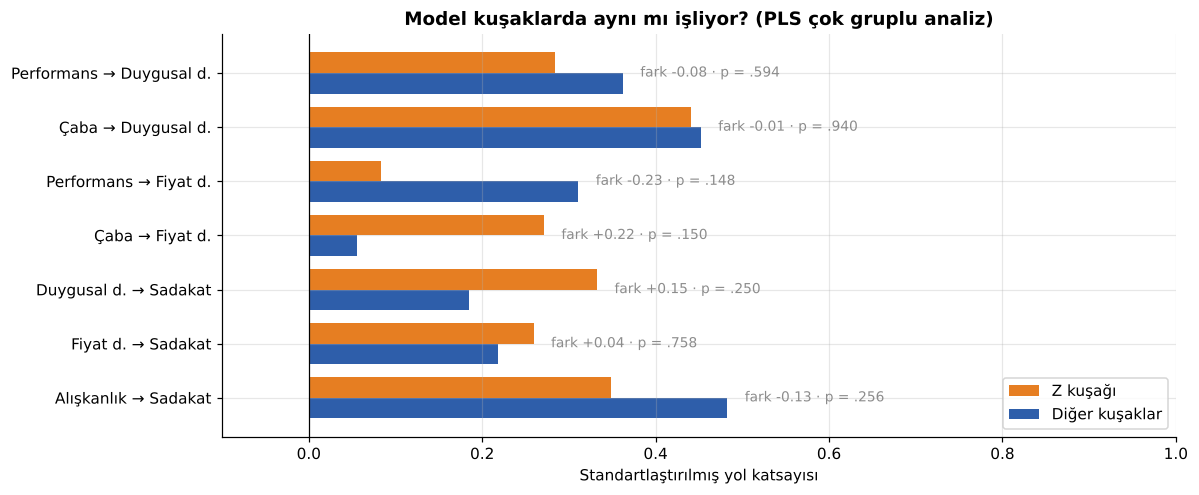

In [10]:
mga = ka.pls_mga(d, model, n_perm=500)
display(mga.style.format(precision=3, na_rep=""))
ka.grafik_mga(mga)

**Yorum:** Hiçbir yol katsayısı kuşaklar arasında anlamlı farklılaşmıyor. Kuşaklar sadakate **aynı yoldan** ulaşıyor; "kuşak çatışması" mekanizmada değil, bu mekanizmayı besleyen algıların seviyesinde yaşanıyor (bkz. 3. bölüm).

## 7. Önem-performans haritası

Her yapının sadakat üzerindeki **toplam etkisi** (önem) ile katılımcıların o yapıyı ne kadar olumlu değerlendirdiği (performans, 0–100) karşılaştırılır. Sağ alt bölge (yüksek önem, düşük performans) öncelikli iyileştirme alanıdır.

,yapı,önem (toplam etki),performans (0-100)
0,Performans beklentisi,0.119,78.886
1,Çaba beklentisi,0.169,80.498
2,Duygusal değer,0.277,69.445
3,Fiyat değeri,0.223,56.500
4,Alışkanlık,0.398,46.269


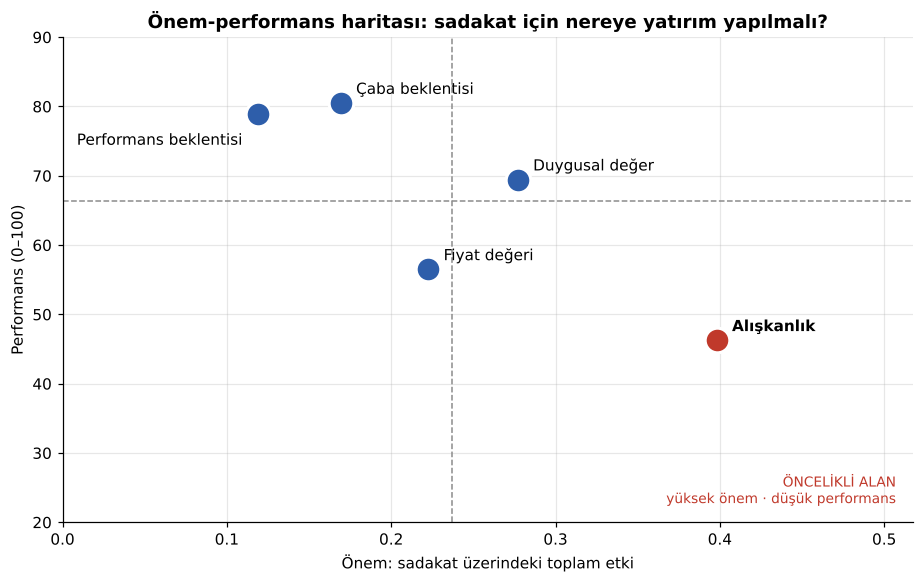

In [11]:
ipma = ka.ipma_analizi(d, pls)
display(ipma.drop(columns="kod").style.format(precision=3))
ka.grafik_ipma(ipma)

**Yorum:** **Alışkanlık**, sadakate en çok katkı yapan ama en düşük performans gösteren yapı: uygulamalar için en büyük fırsat, rutin oluşturan özelliklerde (tek tıkla tekrar sipariş, abonelik, seri ödülleri). Kullanım kolaylığı ve performans zaten yüksek: bunlar artık fark yaratan değil, olmazsa olmaz özellikler.

## 8. Güç analizi: 236 kişi yeterli mi?

In [12]:
ka.guc_analizi(len(d), int((d.kusak == "Z").sum()), int((d.kusak == "Diğer").sum())).style.format(precision=3)

,test,orta etki için gereken n,küçük etki için gereken n,mevcut n,en küçük saptanabilir etki,orta etkiyi yakalama gücü
0,Regresyon / PLS yolu (3 yordayıcı): Sadakat ← duygusal değer + fiyat değeri + alışkanlık,77,550,236,f² = 0.047,1.000
1,Regresyon / PLS yolu (2 yordayıcı): Duygusal / fiyat değeri ← performans + çaba,68,485,236,f² = 0.041,1.000
2,"Kuşak karşılaştırması (t-testi, 129 vs 107)",128,788,236,d = 0.368,0.968


**Yorum:** Orta büyüklükteki etkileri yakalamak için sadakat modelinde 77, kuşak karşılaştırmasında 128 kişi yeterli; 236 kişilik örneklem bu etkileri neredeyse kesin olarak yakalıyor. Küçük etkiler için ise 500'ü aşkın katılımcı gerekirdi. Bu yüzden anlamlı çıkmayan küçük farklar (ör. 6. bölümdeki yol farkları) "etki yok" değil, "bu örneklemle saptanamadı" şeklinde yorumlanmalı.

---

## Sonuç

| Bulgu | Kanıt |
|---|---|
| Sadakatin en güçlü yordayıcısı alışkanlık | PLS β ≈ 0,40 |
| Duygusal değerin ana kaynağı kullanım kolaylığı | f² ≈ 0,29 |
| Z kuşağı daha az alışkanlık, duygusal ve fiyat değeri algılıyor | t-testleri, p < ,05 |
| Sadakat mekanizması kuşaklarda aynı | PLS-MGA, tüm p > ,13 |
| Kötü ekonomik algıda duygu değil fiyat belirleyici | Moderasyon p = ,003 / ,029 |
| Öncelikli iyileştirme alanı: alışkanlık | Önem-performans haritası |

Tüm tablolar [`results/tablolar`](../results/tablolar), R ile yapılan CFA/SEM sağlamlık kontrolü [`results/R/sonuclar.md`](../results/R/sonuclar.md) dosyasındadır.